# Basic-Chemical-to-Pharma — U.S. Pharmaceutical Manufacturing
### Reproduced fixed-snapshot macro-factor falsification, 2026-10-26

**No PIT and no equity alpha established.** This notebook is the independently readable companion to the 15-section README; numerical outputs are executed and saved.

In [1]:
%matplotlib inline
from pathlib import Path
import json, hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from run_analysis import read_data,make_panel,walk_forward,score,improvement,block_bootstrap
ROOT=Path('.')
m=json.loads((ROOT/'results/metrics.json').read_text())
raw=read_data();panel=make_panel(raw);oos=walk_forward(panel)
assert len(raw)==m['n_months'] and len(oos)==m['oos_n']
assert np.isclose(improvement(oos),m['rmse_improvement_macro_minus_full_pp'])
print('Data rows:',len(raw),'OOS origins:',len(oos),'raw SHA:',m['raw_sha256'][:20])
%matplotlib inline

Data rows: 201 OOS origins: 111 raw SHA: 472fcd3f515a862a98a5


## 01. Abstract

**Research question.** Does basic-chemical manufacturing output growth relative to aggregate manufacturing anticipate future U.S. pharmaceutical/medicine production beyond pharmaceutical persistence and the general manufacturing cycle?

**Design.** Three Federal Reserve G.17 industrial-production series, observed monthly from 2010-01 to 2026-09 (**201 months**), are frozen from the 2026-10-26 FRED CSV retrieval. At forecast origin *t*, all inputs are lagged two months, and the outcome is the log change in pharmaceutical output from *t−2* through *t+6*. An expanding-window, 8-month-purged forecast comparison scores **111 OOS origins**, 2017-01-01–2026-03-01.

**Result.** Basic-chemical augmentation raises RMSE from **3.953** to **4.104** percentage points (macro minus full = **-0.151 pp**); a 2,000-draw 12-month moving-block bootstrap interval is **[-0.504, 0.189] pp**. The 1,000-refit exploratory block-shuffle tail fraction is **0.925**. **Verdict: negative retrospective macro-factor pilot; no verified point-in-time or equity alpha.**

In [2]:
display(pd.DataFrame(m['metrics']).T.round(4)); print('Primary ΔRMSE:',round(m['rmse_improvement_macro_minus_full_pp'],5))

,rmse,mae
mean,4.3469,3.7930
persistence,4.4506,3.8984
macro,3.9532,3.4439
full,4.1038,3.4789
gap_only,4.5188,3.8147


Primary ΔRMSE: -0.15062


**Interpretation.** The macro control wins the predeclared comparison. A stronger industry growth narrative would not change the sign of the measured paired loss.

## 02. Research Design & Hypotheses

**H1 (incremental predictive value):** an ex-ante fixed basic-chemical-vs-manufacturing gap improves 6-month pharmaceutical-output forecasts relative to pharmaceutical autoregression plus manufacturing growth. **Null H1:** no paired OOS RMSE improvement.

**H2 (mechanism):** an upstream basic-chemical supply/demand cycle propagates into downstream drug manufacturing with a multi-month lag; this is only a hypothesis, not proof of a company-specific chemical input bill. **Null H2:** upstream movement is macro noise or demand driven, not a lead.

**H3 (stability):** improvement remains directionally positive across forecast horizons, release buffers, pandemic regimes, 72-month rolling training, stale-factor ablation and plausible exposure weights. **Null H3:** the effect is unstable or reverses.

The tests are **predictive**, not causal. There is no clean holdout reserved after selecting this industry and factor, so reported robustness is exploratory. A negative finding is an acceptable endpoint.

In [3]:
assert all(x in panel.columns for x in ['pharma_yoy','pharma_3m','manuf_yoy','chem_yoy','gap','target']);display(panel[['pharma_yoy','chem_yoy','manuf_yoy','gap','target']].head())

,pharma_yoy,chem_yoy,manuf_yoy,gap,target
date,,,,,
2011-03-01,-1.868948,5.952553,5.113332,0.083726,-1.542680
2011-04-01,0.500202,4.369958,5.268898,-0.089653,0.613356
2011-05-01,-0.304239,3.735100,4.640323,-0.090276,-0.057352
2011-06-01,-1.267045,-3.613394,3.208422,-0.592936,1.582075
2011-07-01,-0.362053,-6.877256,1.914546,-0.706008,0.155032


## 03. Industry Context

**Scope.** U.S. pharmaceutical and medicine manufacturing (NAICS 3254) and basic chemical manufacturing (NAICS 3251) are separate Federal Reserve G.17 output aggregates. The proposed chain is chemical intermediates/inputs → drug synthesis/formulation → pharmaceutical production. This aggregation also captures products unrelated to pharmaceuticals, creating substantial signal dilution.

**Growth context, not a forecast.** In the frozen G.17 snapshot, pharmaceutical output moves from 119.6808 in January 2010 to 124.2706 in September 2026, while basic-chemical output moves from 99.3774 to 91.2835 (both 2017=100 indexes). These are historical index endpoints, not annual market-size estimates or investable revenue. Product demand, patent cliffs, generic penetration, biologics and overseas production may dominate any domestic upstream relationship. No unverified market-size/CAGR figures are asserted.

**Counterthesis.** Modern biologic manufacturing is not proportional to broad U.S. basic-chemical production. Global procurement and contract manufacturing can disconnect domestic industry indexes; aggregate manufacturing can also subsume both series mechanically.

In [4]:
display(pd.DataFrame({'first':raw.iloc[0], 'last':raw.iloc[-1], 'percent_change':100*(raw.iloc[-1]/raw.iloc[0]-1)}).round(3))

,first,last,percent_change
PHARMA,119.681,124.271,3.835
CHEM,99.377,91.284,-8.145
MANUF,89.772,99.436,10.766


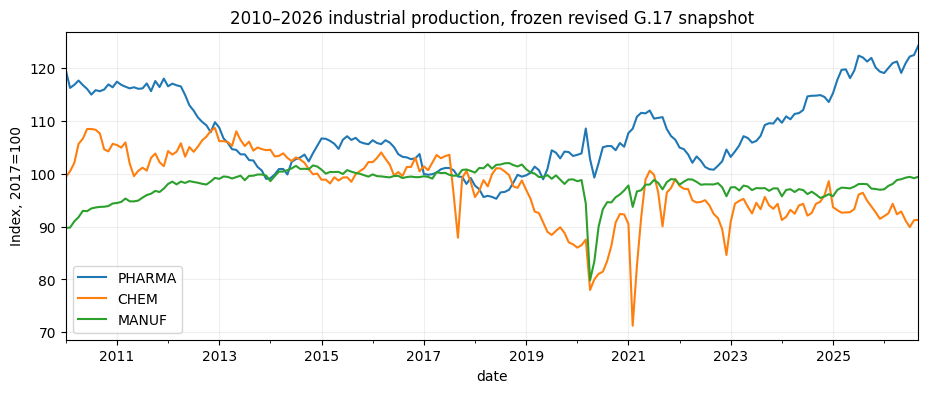

In [5]:
ax=raw.plot(figsize=(11,4),title='2010–2026 industrial production, frozen revised G.17 snapshot');ax.set_ylabel('Index, 2017=100');ax.grid(alpha=.2);plt.show()

**Economic caution.** Aggregate industrial-production indices cannot identify branded pharmaceutical demand, patent exclusivity, or drugmaker equity returns.

## 04. Data & Source Integrity

All **201 × 3** index values come from the Federal Reserve Board's G.17 release as distributed through the public FRED CSV graph endpoints. Frozen raw input: `data/official_snapshot.csv` (2010-01–2026-09); SHA-256 **`472fcd3f515a862a98a5f13b4005262ee6b6716548d7cd5b42155ad03483e5f8`**. The three original series are `IPG3254S` (pharma), `IPG3251S` (basic chemicals), `IPMAN` (aggregate manufacturing), each seasonally adjusted and indexed to 2017=100.

The FRED pages show September 2026 observations updated **2026-10-16**; extraction date is **2026-10-26**. Data were copied from machine-readable CSV and cross-checked against source record count, column sums and squared sums; the frozen snapshot is supplied for independent reproduction. `data/source_register.csv` contains publisher, exact URLs, dates, grade, units, revision policy and unknown fields.

**Source hierarchy:** A = Federal Reserve original statistics and calendar; B = institutional third-party series (not used); C = press or anecdotal commentary (not used). No synthetic observations or privately restricted data are used.

In [6]:
register=pd.read_csv('data/source_register.csv');display(register[['series_id','grade','publisher','latest_source_release_date','pit_status']]);print('SHA256 verified:',hashlib.sha256(Path('data/official_snapshot.csv').read_bytes()).hexdigest()==m['raw_sha256'])

,series_id,grade,publisher,latest_source_release_date,pit_status
0,IPG3254S,A,Federal Reserve Board via FRED,2026-10-16,REVISED_SNAPSHOT_NOT_PIT
1,IPG3251S,A,Federal Reserve Board via FRED,2026-10-16,REVISED_SNAPSHOT_NOT_PIT
2,IPMAN,A,Federal Reserve Board via FRED,2026-10-16,REVISED_SNAPSHOT_NOT_PIT
3,G.17 release calendar,A,Federal Reserve Board,2026-10-16,RELEASE_CALENDAR_ONLY


SHA256 verified: True


In [7]:
print('Missing values:',raw.isna().sum().to_dict());print('Monthly continuity:',len(pd.period_range(raw.index.min(),raw.index.max(),freq='M'))==len(raw))

Missing values: {'PHARMA': 0, 'CHEM': 0, 'MANUF': 0}
Monthly continuity: True


## 05. Point-in-Time Availability

**Critical failure of the strict PIT gate.** This is a **2026-10-26 revised historical snapshot**, not a reconstruction of what investors actually knew in 2010–2026. Historical source publication timestamps and original vintages for every individual observation are **UNKNOWN**. The G.17 release calendar confirms a monthly schedule and the 2026-10-16 release, but does not prove older revised values were known at their forecast origins.

For an origin at month-end *t*, the design only uses index observations through *t−2*, deliberately leaving a two-month publication buffer. Training labels for origin *u* enter the model only when *u+6+2 ≤ t*. **Neither safeguard cures revisions/backfills**: a proper PIT implementation requires ALFRED or original G.17 archive vintages and as-of timestamps, which were not retrieved.

**Verdict for this gate:** retrospective association/falsification only. No executable signal date, price formation or trade timing is claimed.

In [8]:
print('At origin',panel.index[0].date(),'lagged pharma growth is',round(panel.iloc[0].pharma_yoy,3),'pp; latest feature date = origin - 2 months')

At origin 2011-03-01 lagged pharma growth is -1.869 pp; latest feature date = origin - 2 months


## 06. Factor Construction

Let \(P_t\) be pharmaceutical output, \(C_t\) basic-chemical output, and \(M_t\) aggregate manufacturing, all strictly positive seasonally adjusted indexes. Define lagged 12-month log growth \(g^X_t=100[\log X_{t-2}-\log X_{t-14}]\). The fixed factor is

\[F_t=\tanh\{[g^C_t-g^M_t]/10\}.\]

The 10-percentage-point scale is **fixed**, not tuned on the target. A positive value means upstream chemicals have grown faster than manufacturing. The outcome is \(Y_t=100[\log P_{t+6}-\log P_{t-2}]\), an **eight-month interval** from the latest presumed available observation to the six-month-forward endpoint; do not mislabel this as a pure six-month growth rate. All models use the same origins and target.

The factor is neither a company revenue exposure nor a security-return forecast. Manufacturing contains chemical/pharma industries; shared components can create mechanical correlation.

In [9]:
display(panel[['pharma_yoy','pharma_3m','chem_yoy','manuf_yoy','gap','target']].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
pharma_yoy,181.0,0.196,5.081,-10.751,-3.645,0.547,4.621,11.549
pharma_3m,181.0,0.043,2.139,-6.229,-1.216,-0.020,1.401,5.829
chem_yoy,181.0,-0.777,6.708,-19.413,-4.087,-1.367,2.632,31.059
manuf_yoy,181.0,0.338,3.607,-21.892,-0.882,0.445,1.835,19.336
gap,181.0,-0.103,0.417,-0.895,-0.429,-0.128,0.200,0.989
target,181.0,0.179,3.902,-7.996,-2.935,0.403,3.738,8.155


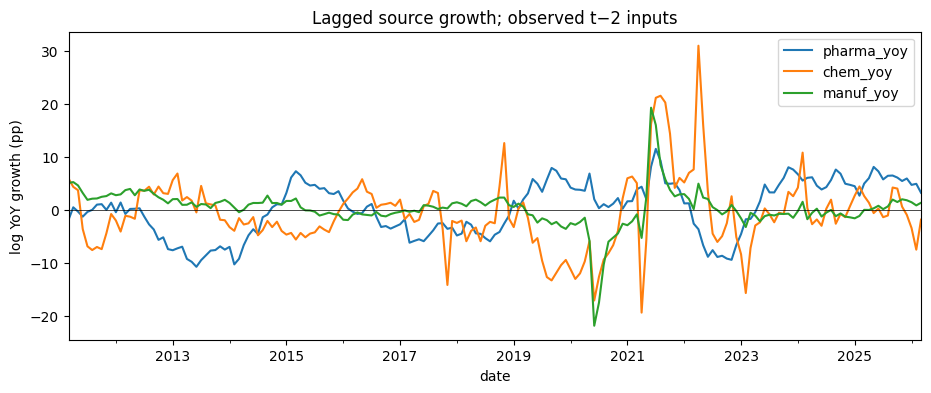

In [10]:
ax=panel[['pharma_yoy','chem_yoy','manuf_yoy']].plot(figsize=(11,4),title='Lagged source growth; observed t−2 inputs');ax.set_ylabel('log YoY growth (pp)');ax.axhline(0,color='black',lw=.5);plt.show()

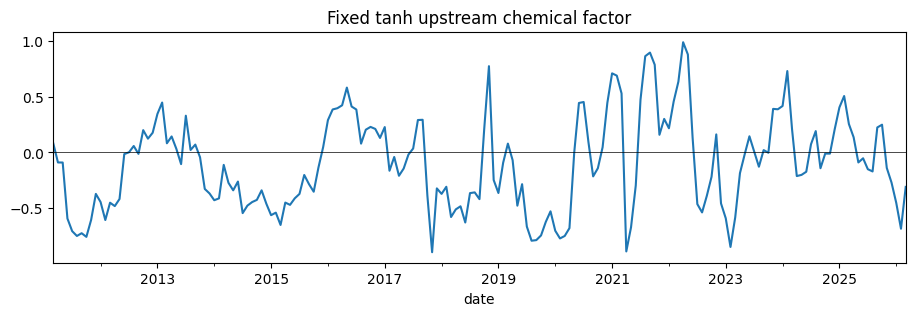

In [11]:
ax=panel.gap.plot(figsize=(11,3),title='Fixed tanh upstream chemical factor');ax.axhline(0,color='black',lw=.5);plt.show()

## 07. Exposure & Transmission

**Industry exposure mapping (qualitative, not a company panel):** chemical manufacturers (NAICS 3251) → possible feedstocks and intermediates → pharmaceutical manufacturers (NAICS 3254). The exposure proxy is a **fixed weight +1.0** on basic-chemical YoY growth and **−1.0** on manufacturing YoY growth. This is an analyst prior and **not** a reported drug-industry chemical cost share.

Exposure perturbation draws 1,000 independent weight pairs uniformly over [0.5, 1.5] and re-runs the complete expanding OOS comparison. No company security identifiers, historical constituent list, firm filings or chemical procurement matrices were acquired. Consequently, **leave-one-company-out, firm revenue lead and equity IC/long-short tests are not applicable and not claimed**. Future research must first construct a contemporaneous manufacturer-to-input mapping from filings.

In [12]:
s=pd.read_csv('results/exposure_1000.csv');display(s.describe(percentiles=[.025,.5,.975]).round(3));print('Fraction improving:',(s.rmse_improvement_pp>0).mean())

,chemical_weight,manufacturing_weight,rmse_improvement_pp
count,1000.000,1000.000,1000.000
mean,1.007,1.013,-0.144
std,0.292,0.284,0.008
min,0.501,0.500,-0.156
2.5%,0.524,0.523,-0.154
50%,1.010,1.005,-0.146
97.5%,1.476,1.471,-0.124
max,1.499,1.500,-0.109


Fraction improving: 0.0


## 08. Outcomes & Baselines

**Target:** 100 × log pharmaceutical output at *t+6* divided by output at *t−2*. **Models:** (i) training-sample historical mean, (ii) pharma 12-month and 3-month growth persistence Ridge, (iii) persistence plus aggregate manufacturing YoY Ridge, (iv) same controls plus the fixed upstream factor, (v) gap-only Ridge. Ridge α=20 is fixed before analysis; feature means/standard deviations are estimated **only on matured training labels**, and intercept is unpenalized.

**OOS protocol:** origins 2017-01 through 2026-03, expanding training with minimum 48 matured observations; for each origin *t*, only training rows with *u+8≤t* are eligible. All OOS rows have the same realized target. Scores are RMSE and MAE in percentage points. No stock benchmark, Sharpe, IC, long-short returns, costs or capacity are available.

In [13]:
display(oos[['n_train','actual','mean','persistence','macro','full']].head().round(3));print('Minimum mature training labels:',oos.n_train.min());assert oos.n_train.min()>=48

,n_train,actual,mean,persistence,macro,full
date,,,,,,
2017-01-01,63,-1.798,-1.436,-1.360,-0.660,-2.008
2017-02-01,64,-3.001,-1.452,-0.908,-0.358,-0.331
2017-03-01,65,-0.477,-1.519,-2.729,-2.194,-1.781
2017-04-01,66,-0.425,-1.573,-2.943,-2.530,-1.418
2017-05-01,67,-1.862,-1.605,-3.341,-2.920,-1.890


Minimum mature training labels: 63


In [14]:
print('Same OOS rows:',oos[['mean','persistence','macro','full','actual']].notna().all().all());print('Last formation date:',oos.index.max().date())

Same OOS rows: True
Last formation date: 2026-03-01


## 09. Empirical Findings

| Model | OOS RMSE (pp) | MAE (pp) |
|:--|--:|--:|
| Historical mean | 4.347 | 3.793 |
| Pharma persistence | 4.451 | 3.898 |
| Pharma + manufacturing macro | **3.953** | **3.444** |
| Macro + upstream factor | 4.104 | 3.479 |
| Upstream factor only | 4.519 | 3.815 |

The predeclared challenger **loses 0.151 pp of RMSE** versus its macro control across **111** overlapping monthly OOS forecasts. The macro baseline is also better than the historical mean and own-output persistence in this fixed snapshot. Because the target spans overlapping eight-month intervals, 111 forecast origins do not represent 111 independent trials; naive iid t-tests would be misleading. Saved row-level predictions and errors are in `results/oos_forecasts.csv`.

In [15]:
table=pd.DataFrame(score(oos)).T.round(4);display(table);assert np.isclose(table.loc['full','rmse'],m['metrics']['full']['rmse'],atol=.0001)

,rmse,mae
mean,4.3469,3.7930
persistence,4.4506,3.8984
macro,3.9532,3.4439
full,4.1038,3.4789
gap_only,4.5188,3.8147


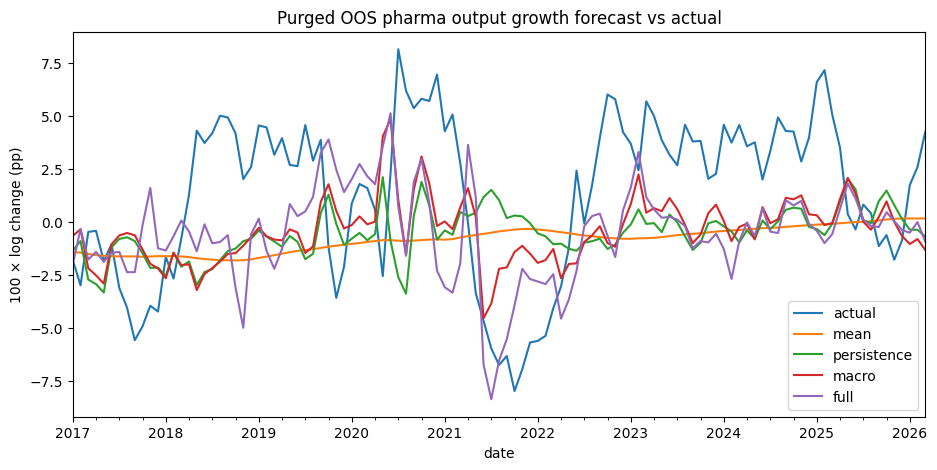

In [16]:
ax=oos[['actual','mean','persistence','macro','full']].plot(figsize=(11,5),title='Purged OOS pharma output growth forecast vs actual');ax.set_ylabel('100 × log change (pp)');plt.show()

count    111.000
mean      -1.214
std       11.461
min      -41.555
25%       -4.719
50%       -0.168
75%        4.112
max       26.815
dtype: float64

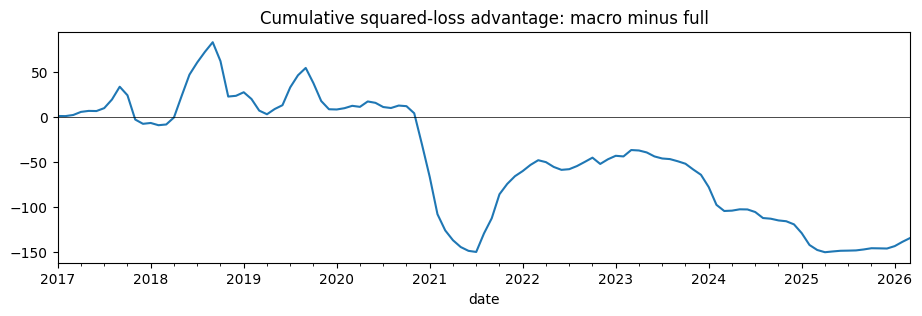

In [17]:
d=(oos.actual-oos.macro)**2-(oos.actual-oos.full)**2;display(d.describe().round(3));ax=d.cumsum().plot(figsize=(11,3),title='Cumulative squared-loss advantage: macro minus full');ax.axhline(0,color='black',lw=.5);plt.show()

**Scoring caution.** The plotted cumulative loss is NOT cumulative portfolio profit or investment return. Monthly outcomes overlap; effective independent sample size is smaller than the row count.

## 10. Robustness & Placebos

**Alignment placebo:** 1,000 complete refits after shuffling non-overlapping 12-month blocks of the factor (the final block may be shorter); one-sided exploratory fraction of placebo improvements ≥ observed = **0.925**. This is **not** an exact exchangeability-based p-value, because blocks are dependent and the null distribution is not guaranteed.

**Uncertainty:** 2,000 circular moving-block bootstrap resamples of the paired OOS forecast-loss rows (block=12 months) yield 95% percentile interval **[-0.504, 0.189] pp** for macro RMSE minus augmented RMSE, including zero. This conditions on already-fitted forecasts and does not re-estimate the full model in each bootstrap.

**Exposure perturbation:** 1,000 weight pairs in [0.5,1.5] each; positive-improvement fraction = **0.000**, central 95% range **[-0.154, -0.124] pp**. This tests chosen prior weights, not true firm exposure.

**Ablations:** a stale 12-month chemical factor, alternate 3-/9-month horizons, three-month publication buffer and 72-month rolling training are calculated and saved. They are sensitivity diagnostics, not separate discoveries.

In [18]:
placebo=pd.read_csv('results/placebo_1000.csv').delta_rmse.to_numpy();boot=pd.read_csv('results/bootstrap_2000.csv').delta_rmse.to_numpy();assert len(placebo)==1000 and len(boot)==2000;display(pd.DataFrame({'placebo':pd.Series(placebo),'bootstrap':pd.Series(boot)}).describe().round(3))

,placebo,bootstrap
count,1000.000,2000.000
mean,-0.043,-0.148
std,0.087,0.180
min,-0.411,-0.867
25%,-0.087,-0.269
50%,-0.048,-0.145
75%,-0.005,-0.024
max,0.300,0.489


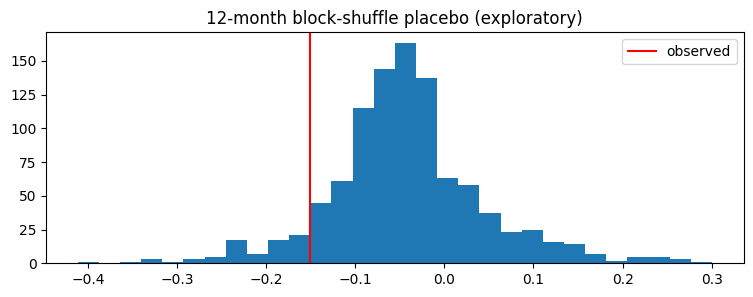

In [19]:
fig,ax=plt.subplots(figsize=(9,3));ax.hist(placebo,bins=30);ax.axvline(improvement(oos),color='red',label='observed');ax.set_title('12-month block-shuffle placebo (exploratory)');ax.legend();plt.show()

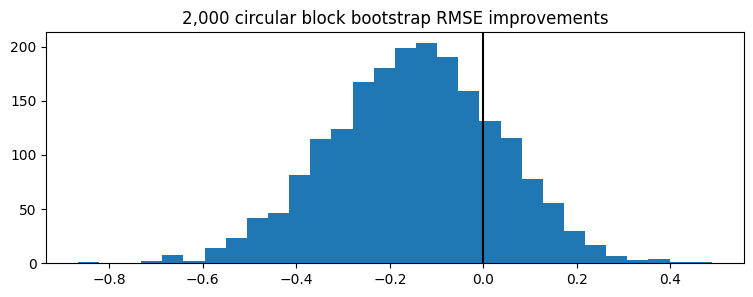

In [20]:
fig,ax=plt.subplots(figsize=(9,3));ax.hist(boot,bins=30);ax.axvline(0,color='black');ax.set_title('2,000 circular block bootstrap RMSE improvements');plt.show()

In [21]:
print('Observed paired ΔRMSE:',round(improvement(oos),4),'pp');print('Block-bootstrap 95% interval:',np.quantile(boot,[.025,.975]).round(4));print('Placebo tail fraction:',round((1+(placebo>=improvement(oos)).sum())/(len(placebo)+1),4))

Observed paired ΔRMSE: -0.1506 pp
Block-bootstrap 95% interval: [-0.5043  0.1889]
Placebo tail fraction: 0.9251


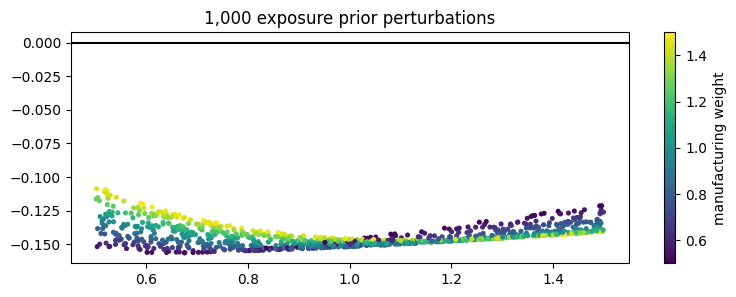

In [22]:
fig,ax=plt.subplots(figsize=(9,3));sc=ax.scatter(s.chemical_weight,s.rmse_improvement_pp,c=s.manufacturing_weight,s=7);ax.axhline(0,color='black');ax.set_title('1,000 exposure prior perturbations');fig.colorbar(sc,ax=ax,label='manufacturing weight');plt.show()

**Placebo interpretation.** These randomization statistics are exploratory diagnostics; the null does not establish exact block exchangeability, and bootstrap conditions on the existing forecast fits.

## 11. Regime Sensitivity

| Evaluation regime | OOS n | Macro minus augmented RMSE (pp) |
|:--|--:|--:|
| Before 2020 | 36 | 0.031 |
| 2020–2021 | 24 | -0.342 |
| 2022 onward | 51 | -0.178 |
| Exclude 2020–2021 | 87 | -0.089 |

**Interpretation:** the small pre-pandemic positive result does not persist in the pandemic or post-pandemic segments. A 72-month rolling training window yields **0.177 pp** improvement, in conflict with the predeclared expanding design. This is model-instability evidence, not permission to switch the headline method after observing results.

| Robustness | OOS n | ΔRMSE (pp) |
|:--|--:|--:|
| horizon_3m | 114 | -0.148 |
| horizon_9m | 108 | -0.121 |
| lag_3m | 111 | -0.123 |
| stale_chemical_12m | 111 | -0.121 |
| rolling_72m | 111 | 0.177 |


In [23]:
reg=pd.DataFrame({k:{'n':v['n'],'delta_rmse':v['improvement_pp']} for k,v in m['regimes'].items()}).T;display(reg.round(3))

,n,delta_rmse
pre_2020,36.0,0.031
2020_2021,24.0,-0.342
post_2021,51.0,-0.178
exclude_2020_2021,87.0,-0.089


In [24]:
rob=pd.DataFrame({k:{'n':v['n'],'delta_rmse':v['delta_rmse']} for k,v in m['robustness'].items()}).T;display(rob.round(3))

,n,delta_rmse
horizon_3m,114.0,-0.148
horizon_9m,108.0,-0.121
lag_3m,111.0,-0.123
stale_chemical_12m,111.0,-0.121
rolling_72m,111.0,0.177


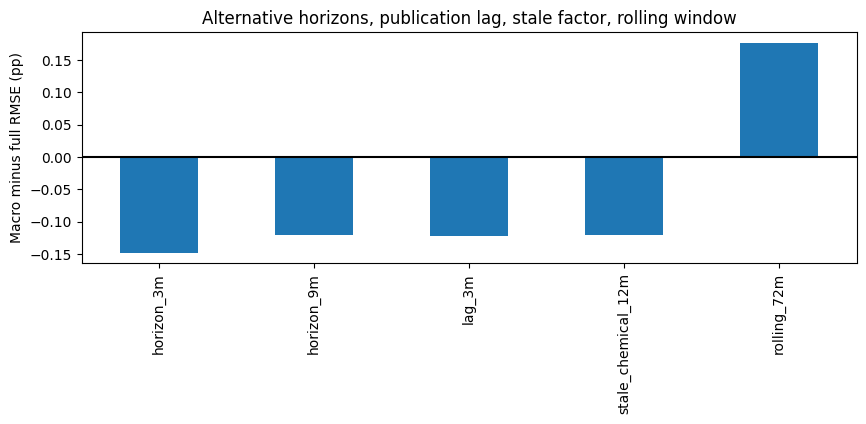

In [25]:
fig,ax=plt.subplots(figsize=(10,3));rob.delta_rmse.plot(kind='bar',ax=ax);ax.axhline(0,color='black');ax.set_ylabel('Macro minus full RMSE (pp)');ax.set_title('Alternative horizons, publication lag, stale factor, rolling window');plt.show()

**Regime caveat.** Positive rolling-window results are post-hoc alternatives to the predeclared expanding-window primary model. They cannot be substituted as headline evidence.

## 12. Bias Audit & Verdict

**Publication/revision leakage: HIGH.** A current FRED history is not a collection of original monthly vintages; lagging by two months cannot cure retroactive index revisions. **Survivorship/selection: HIGH.** The three aggregates and the proposed economic mechanism were selected ex post; no systematic search log or untouched holdout exists. **Mechanical correlation: MEDIUM.** IPMAN includes parts of both studied industries. **Overlap/serial dependence: HIGH.** Eight-month target windows overlap; even 12-month blocks are only an approximation. **Multiple testing: MEDIUM.** Horizons, regimes and weight sensitivity are exploratory and not corrected for multiple comparisons. **Trading costs/capacity: NOT APPLICABLE** because there is no security-level strategy.

**Verdict:** the fixed chemical-production gap fails the primary macro baseline in retrospective OOS and is not a verified PIT, firm-fundamental or investable equity alpha. Its negative result is a falsification of this specific signal and target—not a claim that pharmaceuticals lack investment opportunities.

In [26]:
audit=pd.DataFrame({'risk':['revision leakage','overlap/serial dependence','post-selection','mechanical aggregate overlap','transaction costs'],'status':['HIGH: historical vintages unknown','HIGH: 8m overlapping labels','HIGH: industry chosen ex post','MEDIUM: IPMAN includes sectors','NOT TESTED: no equity strategy']});display(audit)

,risk,status
0,revision leakage,HIGH: historical vintages unknown
1,overlap/serial dependence,HIGH: 8m overlapping labels
2,post-selection,HIGH: industry chosen ex post
3,mechanical aggregate overlap,MEDIUM: IPMAN includes sectors
4,transaction costs,NOT TESTED: no equity strategy


## 13. Reproduction

```bash
python -m pip install -r requirements.txt
python -m pytest tests -q
python compute_heavy.py           # deterministic 1,000 placebo / 1,000 sensitivity / 2,000 bootstrap
jupyter nbconvert --to notebook --execute research.ipynb --output reproduced.ipynb
```

No API key is required because `data/official_snapshot.csv` is frozen. `run_analysis.py` implements the formulas, purged walk-forward and all diagnostics; `compute_heavy.py` parallelizes the expensive refits with fixed seeds. The study's stored outputs were computed on 2026-10-26; `results/execution.log` records the full analysis. All published result values should be recomputed before extending the sample. Data SHA-256: `472fcd3f515a862a98a5f13b4005262ee6b6716548d7cd5b42155ad03483e5f8`.

In [27]:
print('Python re-run: python compute_heavy.py');print('Raw input hash:',m['raw_sha256']);print('Saved figures:',len(list(Path('figures').glob('*.svg'))))

Python re-run: python compute_heavy.py
Raw input hash: 472fcd3f515a862a98a5f13b4005262ee6b6716548d7cd5b42155ad03483e5f8
Saved figures: 8


## 14. Next-Stage Protocol

**Stage 1:** collect monthly as-published Federal Reserve G.17 industry tables/ALFRED vintages and verify the first available date for each series and revision; rerun on original vintage snapshots. **Stage 2:** replace broad chemical output with pharma-specific chemical intermediates and import/export volumes using a contemporaneous product-input crosswalk, without ex-post weight tuning. **Stage 3:** test independent firm fundamentals using SEC 10-K/10-Q filing acceptance timestamps, then separately evaluate a survivorship-free total-return universe after trading costs and sector-neutral controls. **Stage 4:** reserve a genuinely unseen holdout and preregister one primary horizon and null before examining it.

Until these stages succeed, classify the study as **REPRODUCED MACRO PILOT / NOT PIT / NO EQUITY ALPHA**. No future alpha forecast or Sharpe estimate is presented.

In [28]:
print('Next release needed: original G.17 historical vintages + SEC filing as-of fundamentals + security total returns; NONE included in this pilot')

Next release needed: original G.17 historical vintages + SEC filing as-of fundamentals + security total returns; NONE included in this pilot


## 15. Sources & Artifacts

**Primary sources (A):** [Federal Reserve G.17 release and dated calendar](https://www.federalreserve.gov/releases/g17/); [IPG3254S pharmaceutical manufacturing](https://fred.stlouisfed.org/series/IPG3254S); [IPG3251S basic chemicals](https://fred.stlouisfed.org/series/IPG3251S); [IPMAN aggregate manufacturing](https://fred.stlouisfed.org/series/IPMAN). Raw CSV retrievals use `fred.stlouisfed.org/graph/fredgraph.csv?id=<SERIES>`. Historical observation-level publication vintages are **UNKNOWN**.

**Artifacts:** `study.json`, `data/source_register.csv`, `data/official_snapshot.csv`, `data/derived_panel.csv`, `run_analysis.py`, `compute_heavy.py`, `requirements.txt`, `tests/test_pharma.py`, `results/metrics.json`, `results/oos_forecasts.csv`, `results/placebo_1000.csv`, `results/bootstrap_2000.csv`, `results/exposure_1000.csv`, `results/execution.log`, and 8 independently computed SVG figures in `figures/`. `research.ipynb` is an executed narrative/computational record with saved tables and charts.

In [29]:
display(register[['series_id','original_url','original_historical_release_dates','revision_policy']]);print('Final verdict: NEGATIVE retrospective macro factor; PIT / equity alpha unverified')

,series_id,original_url,original_historical_release_dates,revision_policy
0,IPG3254S,https://fred.stlouisfed.org/series/IPG3254S,UNKNOWN,G.17 revised over time and annual revisions
1,IPG3251S,https://fred.stlouisfed.org/series/IPG3251S,UNKNOWN,G.17 revised over time and annual revisions
2,IPMAN,https://fred.stlouisfed.org/series/IPMAN,UNKNOWN,G.17 revised over time and annual revisions
3,G.17 release calendar,https://www.federalreserve.gov/releases/g17/,Historical calendar accessible but original mo...,Annual revisions scheduled


Final verdict: NEGATIVE retrospective macro factor; PIT / equity alpha unverified
